# Archive Explorer

Load, explore, and triage an EVA result archive.
Pipeline: load → visualize → remove training → cluster → filter → score → retrosynthesis → rank.

## Setup

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd

from notebooks.archive_explorer import (
    add_cytotox_scores,
    best_per_cluster,
    display_archive_heatmap,
    draw_grid,
    list_archives,
    load_archive,
    load_training_actives,
    plot_archive_landscape,
    rank_composite,
    remove_training_molecules,
    tag_with_clusters,
    aizynth_score,
    aizynth_find_routes,
    draw_retro_route,
    draw_retro_routes_grid,
)
from notebooks.eva_utils import max_tanimoto_to_set, check_halogenated_benzoic_acid

REPO_ROOT = Path("..").resolve()
TRAINING_CSV = REPO_ROOT / "data" / "predictor" / "predictor_training_data.csv"
CYTOTOX_3T3 = REPO_ROOT / "data" / "cytotox" / "tabpfn_3T3.joblib"
CYTOTOX_HEK = REPO_ROOT / "data" / "cytotox" / "tabpfn_HEK.joblib"

## Select and load archive

In [3]:
archives = list_archives()
print("Available runs:")
for name in archives:
    print(f"  {name}")

RUN = "01_obj_with_minimol"
df = load_archive(archives[RUN])
print(f"\nLoaded {RUN}: {len(df)} molecules")

Available runs:
  01_cmamae_max_partial_charge_restart_100
  01_obj_with_minimol
  02_cmamae_bcut_max_charge_restart_100
  03_cmamae_no_improvement_restart
  04_cmamae_mixed_restart_keepers
  05_cmamae_obj_ranker
  06_cmamae_obj_ranker_mixed_restarts
  cmamae_max_partial_charge_baseline
  test

Loaded 01_obj_with_minimol: 304 molecules


## Archive heatmap

Visualize the 2D behavior space of the archive.

In [4]:
run_dir = REPO_ROOT / "results" / RUN
display_archive_heatmap(run_dir, dimension_names=["bcut2d_logplow", "vsa_estate2"])

<Figure size 800x600 with 2 Axes>

## Remove training molecules

In [5]:
training_actives = load_training_actives(TRAINING_CSV)
df_novel = remove_training_molecules(df, training_actives)
print(f"Novel (non-training): {len(df_novel)} / {len(df)}")

Novel (non-training): 303 / 304


## Max Tanimoto similarity to training set

In [6]:
max_sims, most_similar = max_tanimoto_to_set(
    df_novel["smiles"].tolist(), training_actives
)
df_novel["max_tanimoto_similarity"] = max_sims
df_novel["similar_training_smiles"] = most_similar
print(
    f"Max sim: min={max_sims.min():.3f}, median={np.median(max_sims):.3f}, max={max_sims.max():.3f}"
)

Max sim: min=0.083, median=0.295, max=0.800


## Cluster (Butina 0.65)

In [5]:
df_novel = tag_with_clusters(df_novel, threshold=0.65)
print(f"Clusters: {df_novel['cluster_id'].nunique()}")
print(df_novel.groupby("cluster_id")["cluster_size"].first().describe())

NameError: name 'df_novel' is not defined

## Filter to P(active) > 0.6

In [7]:
candidates = df_novel[df_novel["p_active"] > 0.5].copy()
print(f"Candidates (P>0.5): {len(candidates)}")

Candidates (P>0.5): 40


## Tag aryl-acid-halogen motif

In [8]:
candidates["has_aryl_acid_halogen"] = candidates["smiles"].apply(
    check_halogenated_benzoic_acid
)
print(candidates["has_aryl_acid_halogen"].value_counts())

has_aryl_acid_halogen
False    38
True      2
Name: count, dtype: int64


## Top by P(active)

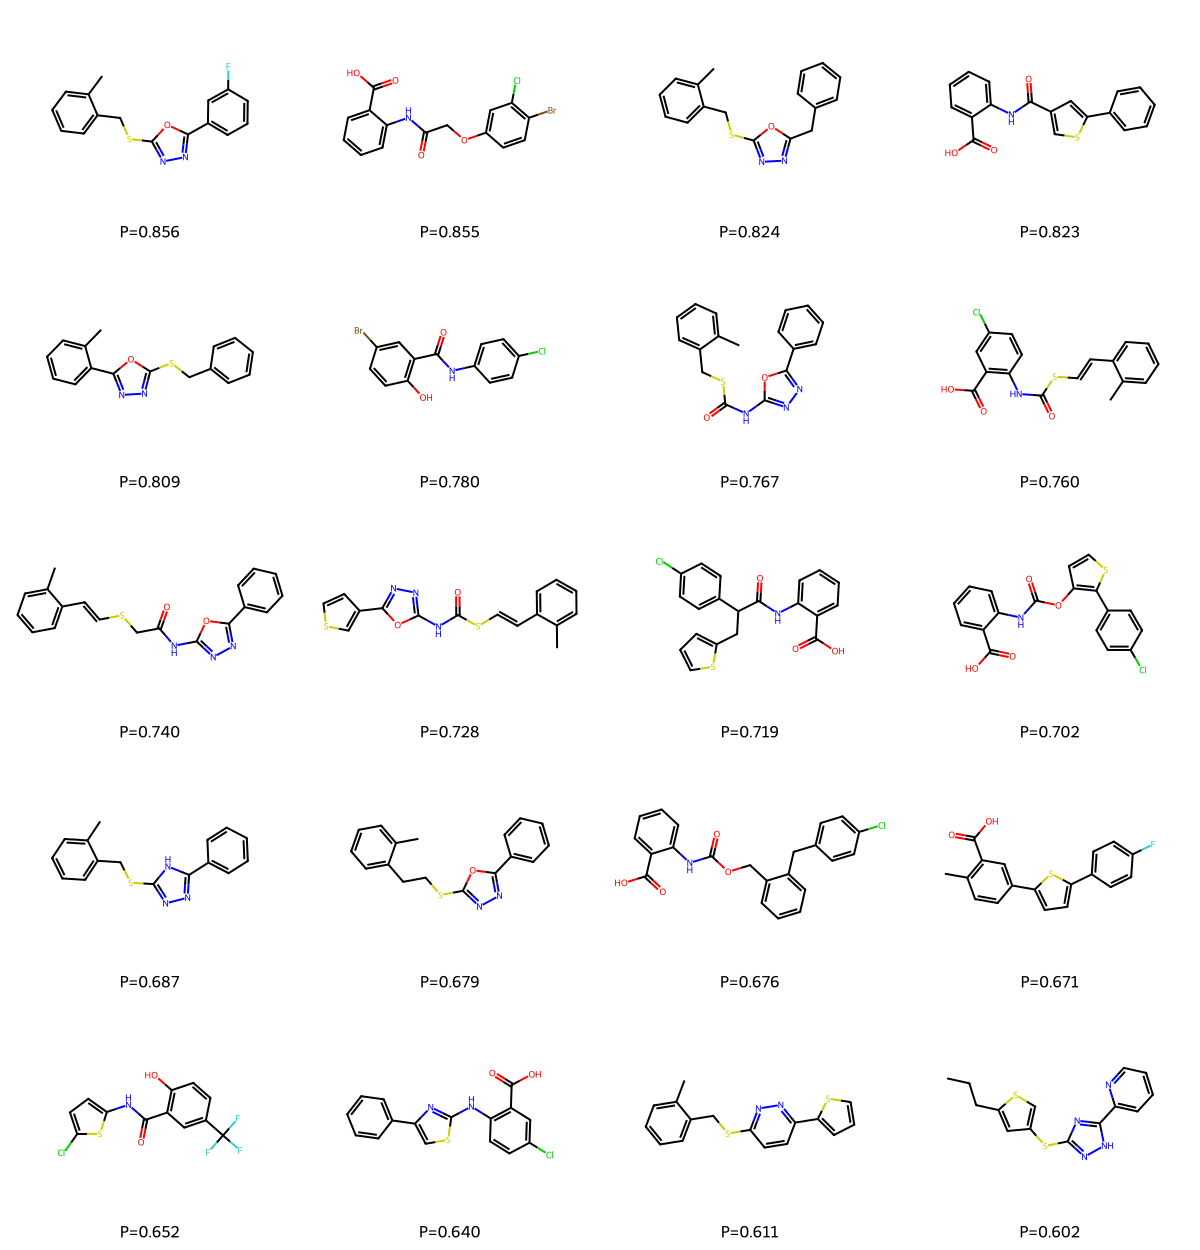

In [9]:
draw_grid(
    candidates.sort_values("p_active", ascending=False).head(20)["smiles"].tolist(),
    mols_per_row=4,
    titles=[
        f"P={p:.3f}"
        for p in candidates.sort_values("p_active", ascending=False).head(20)[
            "p_active"
        ]
    ],
)

## Cytotoxicity scoring (3T3 + HEK)

In [ ]:
candidates = add_cytotox_scores(candidates, CYTOTOX_3T3, column_name="p_cytotox_3T3")
candidates = add_cytotox_scores(candidates, CYTOTOX_HEK, column_name="p_cytotox_HEK")
print(f"3T3: mean={candidates['p_cytotox_3T3'].mean():.3f}")
print(f"HEK: mean={candidates['p_cytotox_HEK'].mean():.3f}")

## AD score

In [ ]:
ad = ADScorer(model_path=AD_MODEL)
fps, valid_idx = [], []
from chemistry.fingerprint import smiles_to_morgan

fps_arr, valid_mask = smiles_to_morgan(candidates["smiles"].tolist())
ad_scores = np.ones(len(candidates))
if fps_arr is not None:
    ad_scores[valid_mask] = ad.compute_from_fps(fps_arr)
candidates["ad_score"] = ad_scores
print(f"AD: mean={candidates['ad_score'].mean():.3f}")

## Retrosynthetic feasibility (AiZynthFinder)

In [ ]:
retro = aizynth_score(
    candidates["smiles"].tolist(),
    time_limit=120,
    n_jobs=8,
)
retro = retro.rename(columns={"top_score": "retro_score", "is_solved": "retro_solved"})
candidates = candidates.merge(
    retro[["smiles", "retro_score", "retro_solved", "n_steps"]], on="smiles", how="left"
)
print(f"Solved: {candidates['retro_solved'].sum()} / {len(candidates)}")

## Composite ranking

In [ ]:
candidates = rank_composite(
    candidates,
    higher_better=["p_active", "retro_score"],
    lower_better=["p_cytotox_3T3", "p_cytotox_HEK"],
    weights={"p_active": 4, "retro_score": 3, "p_cytotox_3T3": 1, "p_cytotox_HEK": 1},
)
draw_grid(
    candidates.head(20)["smiles"].tolist(),
    mols_per_row=4,
    titles=[
        f"#{i+1} P={r['p_active']:.3f} retro={r.get('retro_score', 0):.2f}"
        for i, (_, r) in enumerate(candidates.head(20).iterrows())
    ],
)

In [ ]:
candidates.to_csv(run_dir / "candidates.csv", index=False)

## Best per cluster

In [ ]:
selected = best_per_cluster(candidates, score_col="rank_composite", ascending=True)
print(f"{len(selected)} clusters represented")
draw_grid(
    selected.head(20)["smiles"].tolist(),
    mols_per_row=4,
    titles=[
        f"C{int(r['cluster_id'])} P={r['p_active']:.3f}"
        for _, r in selected.head(20).iterrows()
    ],
)

## Save enriched candidates CSV

In [1]:
out_path = REPO_ROOT / "results" / f"{RUN}_candidates.csv"
candidates.to_csv(out_path, index=False)
print(f"Saved {out_path}")

NameError: name 'REPO_ROOT' is not defined

## Retrosynthetic route for top candidate

In [ ]:
top_smi = selected.iloc[0]["smiles"]
print(f"Top candidate: {top_smi}")
finder = aizynth_find_routes(top_smi)
draw_retro_route(finder, route_idx=0)

In [ ]:
tree = finder.routes.reaction_trees[0]
graph = tree.graph

print("nodes:", graph.nodes)
print("edges:", graph.edges)

for node_id, attrs in graph.nodes(data=True):
    print("\nNODE:", node_id)
    print(attrs)

reaction = next(
    node for node in tree.graph.nodes if type(node).__name__ == "FixedRetroReaction"
)

print(reaction.__dict__)

In [ ]:
draw_retro_routes_grid(finder, n_routes=4, max_cols=2)